Smart Employee Attrition & Performance Prediction

Project Objective

This project uses Machine Learning to analyze employee data,
predict employee attrition, and identify employee groups
based on their characteristics.

Machine Learning Techniques Used

1. Logistic Regression
2. Random Forest



Project Workflow

Data Collection → Data Preprocessing → Exploratory Data Analysis → Model Training → Prediction
→ Model Evaluation → Employee Segmentation


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:

np.random.seed(42)

n = 1000

data = pd.DataFrame({
    "Age": np.random.randint(21, 60, n),
    "MonthlyIncome": np.random.randint(20000, 150000, n),
    "YearsAtCompany": np.random.randint(0, 20, n),
    "JobSatisfaction": np.random.randint(1, 6, n),
    "WorkLifeBalance": np.random.randint(1, 6, n),
    "OvertimeHours": np.random.randint(0, 30, n),
    "ProjectsCompleted": np.random.randint(1, 15, n),
    "TrainingHours": np.random.randint(0, 50, n),
    "PerformanceRating": np.random.randint(1, 6, n)
})

print("Dataset created successfully!")
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

data.head()

Dataset created successfully!
Number of rows: 1000
Number of columns: 9


,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,OvertimeHours,ProjectsCompleted,TrainingHours,PerformanceRating
0,59,77761,17,2,4,11,14,31,3
1,49,141178,18,3,5,7,14,18,4
2,35,56368,4,3,5,23,4,1,1
3,28,26783,8,5,5,15,13,9,5
4,41,131530,2,1,1,17,13,49,4


In [ ]:


risk_score = (
    (data["OvertimeHours"] * 0.08)
    - (data["JobSatisfaction"] * 0.8)
    - (data["WorkLifeBalance"] * 0.5)
    - (data["YearsAtCompany"] * 0.15)
    + (data["ProjectsCompleted"] * 0.05)
)

probability = 1 / (1 + np.exp(-risk_score / 3))

data["Attrition"] = np.random.binomial(1, probability)

print("Attrition column created successfully!")

print("\nAttrition Distribution:")
print(data["Attrition"].value_counts())

data.head()

Attrition column created successfully!

Attrition Distribution:
Attrition
0    751
1    249
Name: count, dtype: int64


,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,OvertimeHours,ProjectsCompleted,TrainingHours,PerformanceRating,Attrition
0,59,77761,17,2,4,11,14,31,3,0
1,49,141178,18,3,5,7,14,18,4,0
2,35,56368,4,3,5,23,4,1,1,0
3,28,26783,8,5,5,15,13,9,5,0
4,41,131530,2,1,1,17,13,49,4,1


In [ ]:


print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nData Types:")
print(data.dtypes)

print("\nStatistical Summary:")
display(data.describe())

Dataset Shape: (1000, 10)

Column Names:
['Age', 'MonthlyIncome', 'YearsAtCompany', 'JobSatisfaction', 'WorkLifeBalance', 'OvertimeHours', 'ProjectsCompleted', 'TrainingHours', 'PerformanceRating', 'Attrition']

Data Types:
Age                  int64
MonthlyIncome        int64
YearsAtCompany       int64
JobSatisfaction      int64
WorkLifeBalance      int64
OvertimeHours        int64
ProjectsCompleted    int64
TrainingHours        int64
PerformanceRating    int64
Attrition            int64
dtype: object

Statistical Summary:


,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,OvertimeHours,ProjectsCompleted,TrainingHours,PerformanceRating,Attrition
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,40.445000,85109.757000,9.377000,3.036000,2.979000,14.718000,7.500000,23.834000,2.979000,0.24900
std,11.499183,37616.261966,5.788123,1.420818,1.424285,8.405065,4.021713,14.202752,1.402329,0.43265
min,21.000000,20060.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.00000
25%,30.000000,52358.750000,4.000000,2.000000,2.000000,8.000000,4.000000,12.000000,2.000000,0.00000
50%,41.000000,83736.000000,9.000000,3.000000,3.000000,14.000000,7.000000,23.000000,3.000000,0.00000
75%,50.000000,116869.250000,14.000000,4.000000,4.000000,22.000000,11.000000,36.000000,4.000000,0.00000
max,59.000000,149972.000000,19.000000,5.000000,5.000000,29.000000,14.000000,49.000000,5.000000,1.00000


In [ ]:


print("Missing Values in Each Column:")
print(data.isnull().sum())

print("\nTotal Duplicate Rows:")
print(data.duplicated().sum())

Missing Values in Each Column:
Age                  0
MonthlyIncome        0
YearsAtCompany       0
JobSatisfaction      0
WorkLifeBalance      0
OvertimeHours        0
ProjectsCompleted    0
TrainingHours        0
PerformanceRating    0
Attrition            0
dtype: int64

Total Duplicate Rows:
0


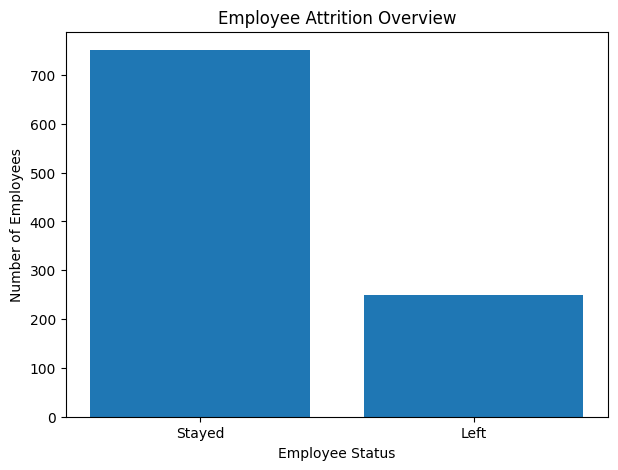

In [ ]:


attrition_counts = data["Attrition"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Stayed", "Left"],
    attrition_counts.reindex([0, 1])
)

plt.title("Employee Attrition Overview")
plt.xlabel("Employee Status")
plt.ylabel("Number of Employees")

plt.show()

In [ ]:


correlation_with_attrition = data.corr()["Attrition"].sort_values()

print("Relationship with Attrition:\n")
print(correlation_with_attrition)

Relationship with Attrition:

WorkLifeBalance     -0.152324
JobSatisfaction     -0.141612
YearsAtCompany      -0.140652
TrainingHours       -0.022100
Age                  0.001246
ProjectsCompleted    0.008342
PerformanceRating    0.025126
MonthlyIncome        0.055976
OvertimeHours        0.111544
Attrition            1.000000
Name: Attrition, dtype: float64


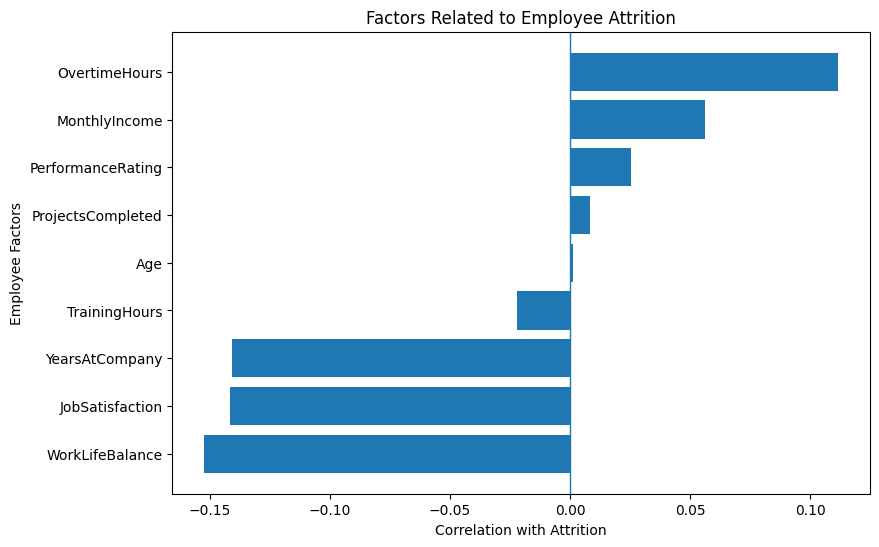

In [ ]:


attrition_correlation = (
    data.corr()["Attrition"]
    .drop("Attrition")
    .sort_values()
)

plt.figure(figsize=(9, 6))

plt.barh(
    attrition_correlation.index,
    attrition_correlation.values
)

plt.title("Factors Related to Employee Attrition")
plt.xlabel("Correlation with Attrition")
plt.ylabel("Employee Factors")

plt.axvline(0, linewidth=1)

plt.show()

In [ ]:


features = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "JobSatisfaction",
    "WorkLifeBalance",
    "OvertimeHours",
    "ProjectsCompleted",
    "TrainingHours",
    "PerformanceRating"
]

X = data[features]
y = data["Attrition"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print("Attrition")

Input features:
['Age', 'MonthlyIncome', 'YearsAtCompany', 'JobSatisfaction', 'WorkLifeBalance', 'OvertimeHours', 'ProjectsCompleted', 'TrainingHours', 'PerformanceRating']

Target variable:
Attrition


In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 9)
Testing data: (200, 9)


In [ ]:


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [ ]:


logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:


logistic_predictions = logistic_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("\nFirst 10 predictions:")
print(logistic_predictions[:10])

Predictions generated successfully!

First 10 predictions:
[0 0 0 0 0 0 0 1 0 0]


In [ ]:


random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:


random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully!")
print("\nFirst 10 predictions:")
print(random_forest_predictions[:10])

Predictions generated successfully!

First 10 predictions:
[0 0 0 0 0 0 0 1 0 0]


In [ ]:


forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

forest_precision = precision_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

forest_recall = recall_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

forest_f1 = f1_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

print("Random Forest Performance")
print("-------------------------")
print(f"Accuracy : {forest_accuracy:.2%}")
print(f"Precision: {forest_precision:.2%}")
print(f"Recall   : {forest_recall:.2%}")
print(f"F1 Score : {forest_f1:.2%}")

Random Forest Performance
-------------------------
Accuracy : 75.00%
Precision: 50.00%
Recall   : 10.00%
F1 Score : 16.67%


In [ ]:


print("Random Forest Classification Report\n")

print(
    classification_report(
        y_test,
        random_forest_predictions,
        target_names=["Stayed", "Left"],
        zero_division=0
    )
)

Random Forest Classification Report

              precision    recall  f1-score   support

      Stayed       0.76      0.97      0.85       150
        Left       0.50      0.10      0.17        50

    accuracy                           0.75       200
   macro avg       0.63      0.53      0.51       200
weighted avg       0.70      0.75      0.68       200



In [ ]:


logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)
logistic_recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)
logistic_f1 = f1_score(
    y_test, logistic_predictions, zero_division=0
)

forest_accuracy = accuracy_score(y_test, random_forest_predictions)
forest_precision = precision_score(
    y_test, random_forest_predictions, zero_division=0
)
forest_recall = recall_score(
    y_test, random_forest_predictions, zero_division=0
)
forest_f1 = f1_score(
    y_test, random_forest_predictions, zero_division=0
)


model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        forest_accuracy
    ],
    "Precision": [
        logistic_precision,
        forest_precision
    ],
    "Recall": [
        logistic_recall,
        forest_recall
    ],
    "F1 Score": [
        logistic_f1,
        forest_f1
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.765,0.666667,0.12,0.203390
1,Random Forest,0.750,0.500000,0.10,0.166667


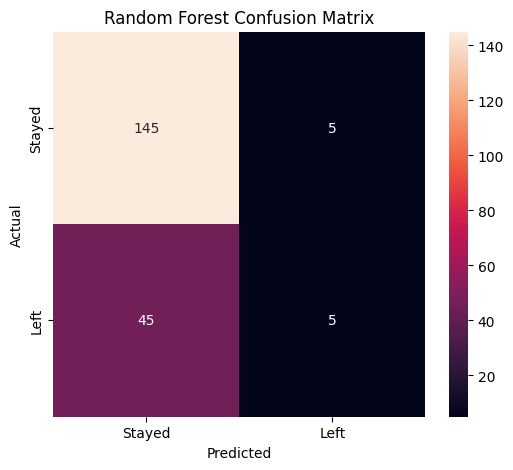

In [ ]:


confusion = confusion_matrix(
    y_test,
    random_forest_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:\n")
display(feature_importance)

Feature Importance:



,Feature,Importance
1,MonthlyIncome,0.176541
5,OvertimeHours,0.149051
2,YearsAtCompany,0.130800
7,TrainingHours,0.121426
0,Age,0.121367
6,ProjectsCompleted,0.096225
3,JobSatisfaction,0.076183
4,WorkLifeBalance,0.074531
8,PerformanceRating,0.053877


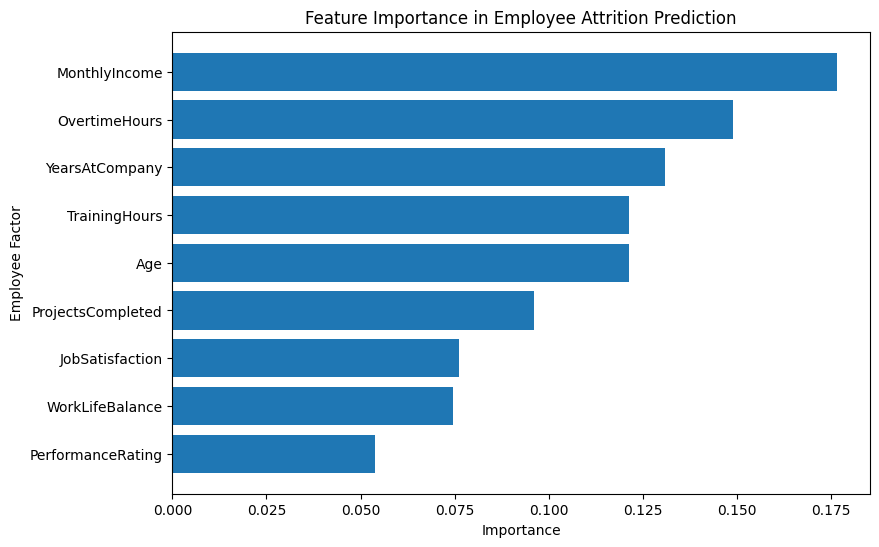

In [ ]:


plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Feature Importance in Employee Attrition Prediction")
plt.xlabel("Importance")
plt.ylabel("Employee Factor")

plt.gca().invert_yaxis()

plt.show()

In [ ]:


balanced_logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_logistic_model.fit(
    X_train_scaled,
    y_train
)

balanced_logistic_predictions = balanced_logistic_model.predict(
    X_test_scaled
)

print("Balanced Logistic Regression model trained successfully!")

Balanced Logistic Regression model trained successfully!


In [ ]:


balanced_accuracy = accuracy_score(
    y_test,
    balanced_logistic_predictions
)

balanced_precision = precision_score(
    y_test,
    balanced_logistic_predictions,
    zero_division=0
)

balanced_recall = recall_score(
    y_test,
    balanced_logistic_predictions,
    zero_division=0
)

balanced_f1 = f1_score(
    y_test,
    balanced_logistic_predictions,
    zero_division=0
)

print("Balanced Logistic Regression Performance")
print("-----------------------------------------")
print(f"Accuracy : {balanced_accuracy:.2%}")
print(f"Precision: {balanced_precision:.2%}")
print(f"Recall   : {balanced_recall:.2%}")
print(f"F1 Score : {balanced_f1:.2%}")

Balanced Logistic Regression Performance
-----------------------------------------
Accuracy : 59.50%
Precision: 30.38%
Recall   : 48.00%
F1 Score : 37.21%


In [ ]:


balanced_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

balanced_forest_model.fit(
    X_train,
    y_train
)

balanced_forest_predictions = balanced_forest_model.predict(
    X_test
)

print("Balanced Random Forest model trained successfully!")

Balanced Random Forest model trained successfully!
